In [1]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

# Load Agent 2 + scaler
with open("../models/agent2_rf.pkl", "rb") as f:
    rf_model = pickle.load(f)
with open("../models/hc_scaler.pkl", "rb") as f:
    hc_scaler = pickle.load(f)

# Load Home Credit test data
with open("../data/clean/hc_data.pkl", "rb") as f:
    _, X_test_hc, _, y_test_hc, feature_names = pickle.load(f)

print("Home Credit test:", X_test_hc.shape)
print("Defaults in test:", y_test_hc.sum(), "/", len(y_test_hc))

Home Credit test: (61503, 79)
Defaults in test: 4965 / 61503


In [2]:
# Load Credit Card test set + Agent 1
with open("../data/clean/cc_data.pkl", "rb") as f:
    _, X_test_cc, _, y_test_cc = pickle.load(f)

import tensorflow as tf
rnn_model = tf.keras.models.load_model("../models/agent1_rnn.h5")

X_test_cc_rnn = X_test_cc.values.reshape((X_test_cc.shape[0], 1, X_test_cc.shape[1]))
rnn_probas_cc = rnn_model.predict(X_test_cc_rnn, verbose=0).flatten()

print("CC fraud probabilities:", rnn_probas_cc.shape)
print("Mean fraud prob:", rnn_probas_cc.mean())
print("Max fraud prob:", rnn_probas_cc.max())

CC fraud probabilities: (56962,)
Mean fraud prob: 0.001838154
Max fraud prob: 0.94175386


In [4]:
# Get Agent 2 probabilities on Home Credit test
X_test_hc_scaled = hc_scaler.transform(X_test_hc)
rf_probas_hc = rf_model.predict_proba(X_test_hc_scaled)[:, 1]

# Bootstrap RNN probabilities to match the length of Home Credit test
np.random.seed(42)
rnn_probas_bootstrapped = np.random.choice(rnn_probas_cc, size=len(rf_probas_hc), replace=True)

# Build Agent 3 training table
X_agent3 = np.column_stack([rnn_probas_bootstrapped, rf_probas_hc])
y_agent3 = y_test_hc.values

print("Agent 3 training table:", X_agent3.shape)
print("First 5 rows:\n", X_agent3[:5])

c:\Users\guerd\anaconda3\envs\credit_project\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


Agent 3 training table: (61503, 2)
First 5 rows:
 [[1.59936862e-05 4.12288930e-01]
 [7.37933851e-06 4.46722619e-01]
 [1.26067289e-05 4.84681765e-01]
 [1.45381537e-05 3.94552429e-01]
 [1.64956436e-05 4.35100318e-01]]


In [5]:
agent3 = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)
agent3.fit(X_agent3, y_agent3)

print("Agent 3 trained.")
print(f"  Coef (rnn, rf): {agent3.coef_[0]}")
print(f"  Intercept: {agent3.intercept_[0]:.4f}")

Agent 3 trained.
  Coef (rnn, rf): [-0.02011639 10.143593  ]
  Intercept: -3.9742


              precision    recall  f1-score   support

           0       0.95      0.57      0.71     56538
           1       0.12      0.65      0.20      4965

    accuracy                           0.57     61503
   macro avg       0.53      0.61      0.45     61503
weighted avg       0.88      0.57      0.67     61503

AUC-ROC: 0.6406826632513413


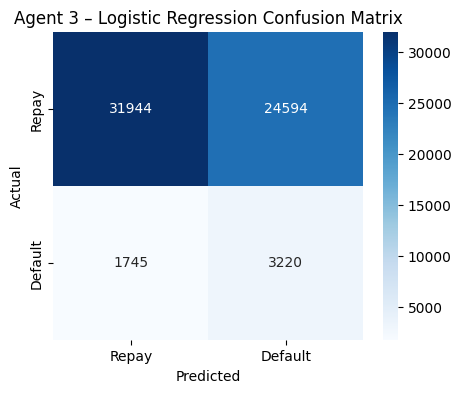

In [6]:
y_pred = agent3.predict(X_agent3)
y_proba = agent3.predict_proba(X_agent3)[:, 1]

print(classification_report(y_agent3, y_pred))
print("AUC-ROC:", roc_auc_score(y_agent3, y_proba))

cm = confusion_matrix(y_agent3, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Repay', 'Default'],
            yticklabels=['Repay', 'Default'])
plt.title("Agent 3 – Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

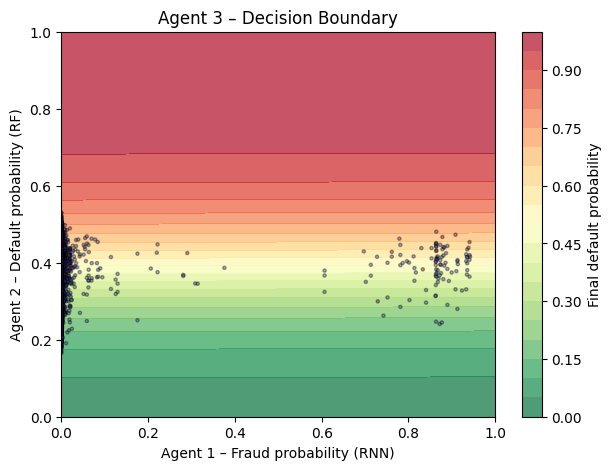

In [7]:
xx, yy = np.meshgrid(np.linspace(0, 1, 200), np.linspace(0, 1, 200))
grid = np.c_[xx.ravel(), yy.ravel()]
Z = agent3.predict_proba(grid)[:, 1].reshape(xx.shape)

plt.figure(figsize=(7, 5))
plt.contourf(xx, yy, Z, levels=20, cmap='RdYlGn_r', alpha=0.7)
plt.colorbar(label='Final default probability')
plt.scatter(X_agent3[:, 0], X_agent3[:, 1], c=y_agent3,
            cmap='coolwarm', edgecolor='k', s=5, alpha=0.4)
plt.xlabel("Agent 1 – Fraud probability (RNN)")
plt.ylabel("Agent 2 – Default probability (RF)")
plt.title("Agent 3 – Decision Boundary")
plt.xlim(0, 1); plt.ylim(0, 1)
plt.show()

In [8]:
import os
os.makedirs("../models", exist_ok=True)

with open("../models/agent3_lr.pkl", "wb") as f:
    pickle.dump(agent3, f)

# Save the HC feature-name order so the Streamlit app maps inputs correctly
with open("../models/hc_feature_names.pkl", "wb") as f:
    pickle.dump(feature_names, f)

print("✅ Saved:")
print("   ../models/agent3_lr.pkl")
print("   ../models/hc_feature_names.pkl")

✅ Saved:
   ../models/agent3_lr.pkl
   ../models/hc_feature_names.pkl
